# 08 - Detection avec YOLO11 (Ultralytics) : boites, boites orientees, instances, tuiles

Ce que tu apprends ici, tout le code etant deroule dans les cellules :

- lire des annotations Pascal VOC a la main et regarder le jeu (classes, objets par image, tailles) ;
- decouper PAR IMAGE avec le meme algorithme que la toolbox, et le verifier ;
- ecrire le jeu au format YOLO (images pretraitees + un .txt par image) ;
- entrainer YOLO11, predire par le chemin de production (lecture -> pretraitement -> modele ->
  retour aux coordonnees d'origine), evaluer au protocole COCO ET au seuil de production ;
- choisir le seuil de confiance sur la VALIDATION ;
- exporter en ONNX, ecrire le post-traitement en numpy (letterbox, NMS) et le verifier ;
- boites orientees (OBB) et segmentation d'instances depuis des masques (Magnetic Tile) ;
- inference par tuiles sur une grande image.

Prerequis : extra `detection` (ultralytics, pycocotools), `python tools/get_data/get_neu_det.py`,
`python tools/get_data/get_magnetic_tile.py`, poids `weights/yolo11n*.pt` (`tools/fetch_weights.py`).
Duree en mode QUICK sur 2 coeurs : 1 a 2 minutes. Licence : Ultralytics est sous AGPL-3.0 (licence
commerciale pour un produit ferme) ; YOLOX (notebook 09) et RF-DETR (11) sont sous Apache-2.0.

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 2 Importer et explorer -> 3 Cataloguer -> 4 Decouper
  -> 5 Pretraiter et 7 Charger par lots (ecrire le jeu au format YOLO, que le moteur lira par lots)
  -> 6 Augmenter, 7 Charger par lots, 8 Modele, 9 Perte et optimiseur, 10 Entrainer
     (un seul appel : Ultralytics fait les cinq)
  -> 13 Predire -> 11 Evaluer -> 12 Sauvegarder et exporter
  -> variante OBB / instances -> 13 Predire (par tuiles)
```

La prediction (13) vient avant l'evaluation (11) : on evalue le chemin de production.

## Etape 1 - Imports et reglages

Deux cellules : d'abord REGLAGES (tout ce qu'on change pour ses propres donnees est la, et
seulement la), puis les imports et la preparation (affichage, graine du hasard).

In [1]:
# REGLAGES : tout ce qu'on change pour ses propres donnees est ici.
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import torch  # PyTorch : tenseurs (tableaux de nombres, sur CPU ou carte graphique) et reseaux ; ici pour detecter la carte graphique

QUICK = True  # True : essai court sur CPU (240 images, 2 epoques) ; False : configuration complete (GPU conseille)

IMAGES_DIR = Path("data/raw/neu_det/IMAGES")  # les images (sous-dossiers acceptes)
ANNOTATIONS_DIR = Path("data/raw/neu_det/ANNOTATIONS")  # un XML Pascal VOC par image, de meme nom
COLOR = "gray"  # "gray" : lecture en niveaux de gris, copiee sur 3 canaux pour le reseau ; "rgb" sinon
PREPROCESS = []  # ex. [{"name": "clahe", "clip_limit": 2.0, "tile_grid": 8}] : noms et parametres de vtb.preprocess
MAX_IMAGES = 240 if QUICK else None  # sous-echantillon fixe (graine 0) pour l'essai rapide
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15  # 15 % des images pour la validation (reglages), 15 % pour le test (mesure finale)
SEED = 42  # graine de la toolbox (runtime.seed) : meme decoupage et meme entrainement que la recette

WEIGHTS = "weights/yolo11n.pt"  # poids COCO ; yolo11s.pt / yolo11m.pt : plus precis, plus lents
IMGSZ = 320  # cote de l'entree du reseau (multiple de 32) ; NEU-DET fait 200 px
EPOCHS = 2 if QUICK else 60  # epoque = un passage complet sur toutes les images d'entrainement
BATCH = 16  # lot (batch) : 16 images traitees ensemble a chaque pas d'apprentissage
PATIENCE = 2 if QUICK else 20  # arret anticipe apres ce nombre d'epoques sans progres sur la validation
CLOSE_MOSAIC = 1 if QUICK else 10  # dernieres epoques sans mosaic (augmentation qui colle 4 images en une)
WARMUP_EPOCHS = 1 if QUICK else 3  # echauffement : le taux d'apprentissage monte progressivement pendant ces epoques

# confiance = score de 0 a 1 que le modele donne a chaque boite ; mAP = precision moyenne de detection (etape 11)
CONF_EVAL = 0.001  # evaluation : toute la courbe precision-rappel (le mAP en a besoin)
CONF_PREDICT = 0.25  # seuil de production de la recette (on le choisit plus bas sur la validation)
# NMS (suppression des non-maxima) : deux boites de meme classe dont l'IoU depasse 0.6 sont un doublon, on garde la meilleure ;
# IoU = aire commune / aire totale des deux boites (0 = disjointes, 1 = identiques)
IOU_NMS = 0.6
VERIFY_CONF = 0.05  # seuil de la verification d'export : assez bas pour avoir des boites a comparer
OPSET = 18  # version du jeu d'operations ONNX (format standard d'echange de reseaux) utilisee a l'export

# Boites orientees et instances (variante OBB / instances) : Magnetic Tile, masques binaires a cote des images
TILE_DIR = Path("data/raw/magnetic_tile")  # MT_<defaut>/Imgs/<nom>.jpg + <nom>.png ; MT_Free = sans defaut
TILE_MAX_IMAGES = 200 if QUICK else None  # nombre d'images Magnetic Tile gardees en mode rapide (None = toutes)
TILE_IMGSZ = 256 if QUICK else 416  # taille d'entree du reseau pour Magnetic Tile
TILE_EPOCHS = 1 if QUICK else 80  # epoques des modeles OBB et instances
TILE_GROUPS_CSV = Path("outputs/explore/magnetic_tile/groups.csv")  # quasi-doublons (notebook 05) ; utilise si QUICK=False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # carte graphique (cuda) si presente, sinon processeur
OUT = Path("outputs/notebooks/08_detection_yolo")  # dossier ou le notebook ecrit ses resultats
# decoupages ecrits par la recette (s'ils existent) : le notebook verifie qu'il retrouve exactement les memes
RECIPE_SPLIT = Path("outputs/detection/quick_split.csv" if QUICK else "outputs/detection/neu_det_split.csv")
RECIPE_TILE_SPLIT = Path("outputs/detection/quick_tile_split.csv" if QUICK else "outputs/detection/tile_split.csv")  # idem Magnetic Tile
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie s'il manque (sans erreur s'il existe)
print("appareil :", DEVICE, "| mode", "QUICK" if QUICK else "complet")  # rappel du materiel et du mode

appareil : cpu | mode QUICK


In [2]:
import contextlib  # contextlib : outils pour les blocs with (ici : rendre muette une fonction bavarde)
import io  # io : fichiers en memoire (ici : une poubelle pour le texte affiche par pycocotools)
import json  # json : lire et ecrire des fichiers texte structures (carte du modele, metriques)
import os  # os : acces au systeme (variables d'environnement)
import platform  # platform : version de Python, notee dans la carte du modele
import shutil  # shutil : copier, deplacer, supprimer des fichiers et des dossiers
import time  # time : chronometre
import xml.etree.ElementTree as ET  # ElementTree : lire les fichiers XML (annotations Pascal VOC)
from collections import Counter  # Counter : compte les occurrences (ex. classe la plus frequente d'une image)
from datetime import UTC, datetime  # datetime : date et heure ; UTC : heure universelle (date de creation du modele)

os.environ["YOLO_VERBOSE"] = "False"  # Ultralytics sans barres de progression ni journal detaille (a regler avant son import)

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import matplotlib.pyplot as plt  # matplotlib : graphiques et affichage d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame) a colonnes nommees, comme une feuille de tableur
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.model_selection import StratifiedGroupKFold, train_test_split  # decoupages au hasard : stratifie, ou par groupes

from vtb import viz  # viz : affichages de la toolbox (grilles d'images, boites dessinees, courbes)

viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en JPEG a 80 points par pouce : notebook plus leger

## Etapes 2 et 3 - Importer et cataloguer : lire les annotations Pascal VOC

Un XML par image : la taille de l'image et, pour chaque objet, un nom de classe et les coins
`xmin, ymin, xmax, ymax` en pixels. Deux pieges classiques :

- `cv2.imread` echoue EN SILENCE (il rend None) sur un chemin Windows avec accents : on lit les
  octets avec numpy puis on decode, ce qui marche partout ;
- certaines annotations debordent d'un pixel : on ramene chaque boite dans l'image.

Representation retenue pour tout le notebook : un enregistrement par image (chemin, taille,
boites `(n, 4)` en pixels de l'image d'ORIGINE, etiquettes).

In [3]:
IMAGE_EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}  # extensions de fichier reconnues comme images


def read_image(path, color="gray"):  # lit un fichier image ; renvoie un tableau (H, W) en gris ou (H, W, 3) en RGB
    """Fichier -> tableau numpy : (H, W) en gris, (H, W, 3) en RGB ; robuste aux chemins Windows."""
    # lit les octets avec numpy puis decode avec OpenCV (chemins accentues OK) ; UNCHANGED garde 8 ou 16 bits
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete tout de suite avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # 4 canaux : couleur + transparence (alpha)
        image = image[:, :, :3]  # canal alpha ignore
    if color == "gray":  # lecture en gris demandee
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image  # couleur -> gris ; deja grise : inchangee
    # sinon RGB : une image couleur passe de BGR (ordre d'OpenCV) a RGB ; une image grise est recopiee sur 3 canaux
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else np.stack([image] * 3, axis=-1)


def write_image(path, image_bgr):  # ecrit une image BGR sur disque ; ne renvoie rien
    """Ecriture robuste aux chemins Windows (le format suit l'extension)."""
    path = Path(path)  # accepte un texte ou un Path
    path.parent.mkdir(parents=True, exist_ok=True)  # cree le dossier parent s'il manque
    ok, buffer = cv2.imencode(path.suffix, image_bgr)  # encode l'image en memoire au format de l'extension (.jpg, .png...)
    if not ok:  # l'encodage a echoue
        raise ValueError(f"encodage impossible : {path}")  # arret avec un message clair
    buffer.tofile(str(path))  # ecrit les octets avec numpy (marche avec les chemins accentues, contrairement a cv2.imwrite)


def to_three_channels(image):  # renvoie l'image sur 3 canaux
    return image if image.ndim == 3 else np.stack([image] * 3, axis=-1)  # deja 3 canaux : inchangee ; grise : recopiee 3 fois


def to_bgr3(image):  # renvoie l'image en BGR sur 3 canaux (ordre attendu par Ultralytics et OpenCV)
    """Ultralytics et OpenCV supposent un tableau BGR ; en gris, les trois canaux sont identiques."""
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2BGR)  # gris : 3 copies ; RGB -> BGR


def read_voc(xml_path):  # lit une annotation Pascal VOC ; renvoie (largeur, hauteur, boites (n, 4), etiquettes)
    """Un XML VOC -> (largeur, hauteur, boites (n, 4), etiquettes) ; boites ramenees dans l'image."""
    root = ET.parse(xml_path).getroot()  # lit le XML et prend sa balise racine <annotation>
    # taille de l'image (float puis int : accepte aussi "200.0")
    width, height = int(float(root.findtext("size/width"))), int(float(root.findtext("size/height")))
    boxes, labels = [], []  # boites et classes des objets de l'image
    for obj in root.iter("object"):  # pour chaque balise <object> (un objet annote)
        b = obj.find("bndbox")  # sa boite englobante
        x1, y1, x2, y2 = (float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))  # coins haut-gauche et bas-droite, en pixels
        # boite ramenee dans l'image (certaines annotations debordent d'un pixel)
        boxes.append([max(0.0, x1), max(0.0, y1), min(float(width), x2), min(float(height), y2)])
        labels.append(obj.findtext("name").strip())  # nom de la classe, sans espaces autour
    return width, height, np.array(boxes, np.float32).reshape(-1, 4), labels  # reshape : forme (0, 4) meme sans objet


def main_label(labels):  # renvoie la classe la plus frequente de l'image
    """Classe la plus frequente de l'image (sert a stratifier) ; "background" pour une image sans objet."""
    return Counter(labels).most_common(1)[0][0] if labels else "background"  # most_common(1) = [(classe, nombre)]


image_paths = sorted(p for p in IMAGES_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)  # toutes les images, triees
records = []  # un enregistrement (dictionnaire) par image
for image_path in image_paths:  # pour chaque image
    xml_path = ANNOTATIONS_DIR / f"{image_path.stem}.xml"  # son annotation : meme nom, extension .xml
    if not xml_path.exists():  # annotation manquante
        raise FileNotFoundError(f"annotation VOC absente pour {image_path.name}")  # arret : sinon l'image passerait pour saine
    width, height, boxes, labels = read_voc(xml_path)  # lit taille, boites et classes
    records.append({"path": str(image_path), "width": width, "height": height, "boxes": boxes, "labels": labels})  # range le tout
CLASS_NAMES = sorted({label for r in records for label in r["labels"]})  # l'ordre alphabetique fixe les indices
CLASS_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}  # nom de classe -> numero
by_path = {r["path"]: r for r in records}  # chemin -> enregistrement, pour retrouver vite une image
print(len(records), "images annotees ;", sum(len(r["labels"]) for r in records), "objets ; classes :", CLASS_NAMES)  # bilan du jeu

1770 images annotees ; 4126 objets ; classes : ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


## Etape 2 - Importer et explorer : regarder les donnees avant d'entrainer

Trois questions : les classes sont-elles equilibrees (en objets, pas en images) ? Combien
d'objets par image ? Quelle taille ont les boites par rapport a l'image ? Une boite qui couvre
toute l'image (ici `crazing`, une texture diffuse) est un objet tres different d'une piqure
de quelques pixels : le detecteur et l'evaluation (IoU) le ressentiront.

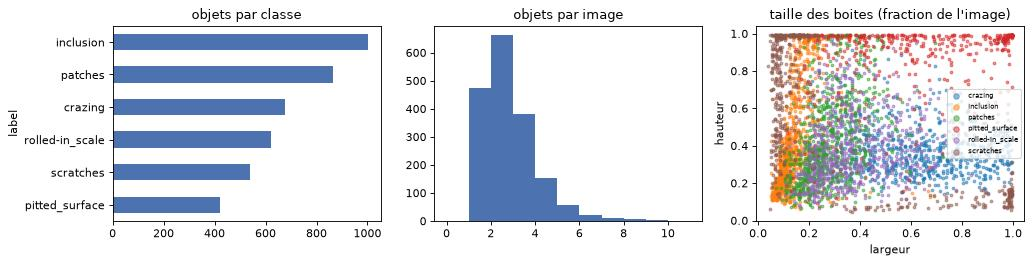

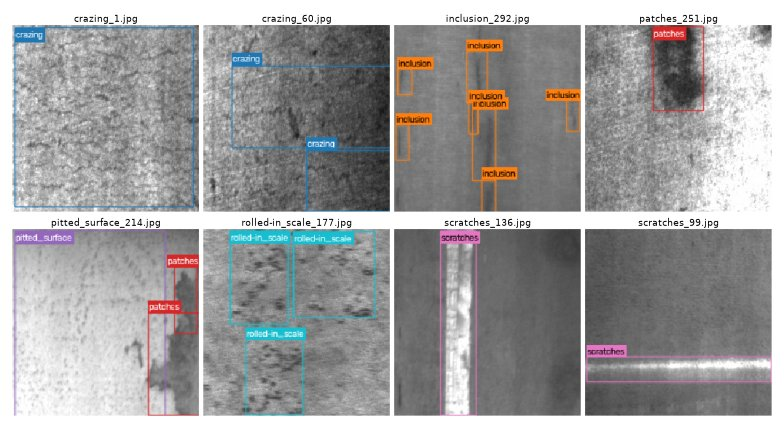

In [4]:
objects = pd.DataFrame(  # tableau des objets : une ligne par boite annotee
    [  # liste construite par comprehension
        {"label": label, "w": b[2] - b[0], "h": b[3] - b[1], "image_w": r["width"], "image_h": r["height"]}  # boite et taille image
        for r in records  # pour chaque image
        for b, label in zip(r["boxes"], r["labels"])  # pour chaque boite de l'image et sa classe
    ]
)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))  # une figure de 3 graphiques cote a cote
objects["label"].value_counts().sort_values().plot.barh(ax=axes[0], color="#4c72b0")  # barres : nombre d'objets par classe
axes[0].set_title("objets par classe")  # titre du 1er graphique
axes[1].hist([len(r["labels"]) for r in records], bins=range(0, 12), color="#4c72b0")  # histogramme : nombre d'objets par image
axes[1].set_title("objets par image")  # titre du 2e graphique
for label, group in objects.groupby("label"):  # pour chaque classe et ses objets
    # un point par boite : largeur et hauteur en fraction de l'image (divisees par la largeur : NEU-DET est carre)
    axes[2].scatter(group["w"] / group["image_w"], group["h"] / group["image_h"], s=6, alpha=0.5, label=label)
axes[2].set_title("taille des boites (fraction de l'image)")  # titre du 3e graphique
axes[2].set_xlabel("largeur")  # nom de l'axe horizontal
axes[2].set_ylabel("hauteur")  # nom de l'axe vertical
axes[2].legend(fontsize=6, markerscale=2)  # legende des classes (petite police, points agrandis)
plt.tight_layout()  # resserre la mise en page sans chevauchement
plt.show()  # affiche la figure

shown = [records[i] for i in np.linspace(0, len(records) - 1, 8).astype(int)]  # 8 images reparties regulierement dans le jeu
viz.grid(  # planche d'images
    [  # chaque image avec ses boites dessinees
        # lit l'image et dessine ses vraies boites, avec le nom de la classe
        viz.draw_boxes(read_image(r["path"], COLOR), r["boxes"], labels=[CLASS_INDEX[x] for x in r["labels"]], class_names=CLASS_NAMES)
        for r in shown  # pour chacune des 8 images
    ],
    [Path(r["path"]).name for r in shown],  # titres : noms de fichier
    ncols=4,  # 4 colonnes
    size=2.4,  # taille de chaque case
)
plt.show()  # affiche la planche

## Etape 4 - Decouper : PAR IMAGE, une fois pour toutes

On decoupe des images, pas des objets : tous les objets d'une image restent du meme cote.
La stratification se fait sur la classe principale de chaque image. C'est EXACTEMENT
l'algorithme de `vtb.split` (meme sous-echantillon, meme graine, memes appels a
`train_test_split`) : la cellule compare au decoupage de la recette s'il existe. Le decoupage
est ecrit dans `split.csv` et relu ensuite : on n'y touche plus.

In [5]:
def can_stratify(labels, fraction):  # vrai si on peut stratifier (garder la proportion de chaque classe) pour ce prelevement
    """Il faut au moins 2 images par classe et assez d'images pour chaque classe dans la part prelevee."""
    counts = labels.value_counts()  # nombre d'images par classe
    # plusieurs classes, au moins 2 images par classe, et une part prelevee assez grande pour contenir chaque classe
    return len(counts) > 1 and counts.min() >= 2 and fraction * len(labels) >= len(counts)


def holdout_stratified(index, labels, fraction, seed):  # preleve une part des lignes, stratifiee si possible ; renvoie leurs index
    stratify = labels if can_stratify(labels, fraction) else None  # sinon tirage simple au hasard
    _, held = train_test_split(index, test_size=fraction, stratify=stratify, random_state=seed)  # on garde seulement la part prelevee
    return pd.Index(held)  # sous forme d'index pandas


def holdout_grouped(frame, fraction, seed):  # preleve environ fraction des lignes sans couper de groupe ; renvoie leurs index
    """Prelever ~fraction des lignes sans couper aucun groupe (meme piece, meme tuile) : premier pli d'un StratifiedGroupKFold."""
    # coupe en k plis (k = 1 / fraction) : chaque groupe reste entier dans un pli, les classes restent equilibrees
    folds = StratifiedGroupKFold(n_splits=max(2, round(1 / fraction)), shuffle=True, random_state=seed)
    _, held = next(folds.split(frame, frame["label"].astype(str), groups=frame["group"]))  # premier pli : positions des lignes prelevees
    return frame.index[held]  # positions -> index du tableau


# make_split : ajoute au catalogue une colonne split (train / val / test) ; renvoie le tableau complete
def make_split(catalog, val_fraction, test_fraction, seed, grouped=False):
    catalog = catalog.copy().reset_index(drop=True)  # copie renumerotee 0, 1, 2... (l'original n'est pas modifie)
    labels = catalog["label"].astype(str)  # classe principale de chaque image, en texte
    catalog["split"] = "train"  # par defaut : entrainement
    if grouped:  # decoupage par groupes (meme piece, quasi-doublons)
        catalog.loc[holdout_grouped(catalog, test_fraction, seed), "split"] = "test"  # d'abord le test
        rest = catalog[catalog["split"] == "train"]  # le reste
        # puis la validation, en part du reste
        catalog.loc[holdout_grouped(rest, val_fraction / (1 - test_fraction), seed), "split"] = "val"
    else:  # decoupage stratifie image par image
        catalog.loc[holdout_stratified(catalog.index, labels, test_fraction, seed), "split"] = "test"  # d'abord le test
        rest = catalog[catalog["split"] == "train"]  # le reste
        # validation : 0.15 / 0.85 du reste = 15 % du total
        val = holdout_stratified(rest.index, labels[rest.index], val_fraction / (1 - test_fraction), seed)
        catalog.loc[val, "split"] = "val"  # marque la validation
    if "group" in catalog:  # une fuite = un groupe present dans deux sous-ensembles
        # chaque groupe doit tomber dans un seul sous-ensemble, sinon arret avec ce message
        assert catalog.groupby("group")["split"].nunique().max() == 1, "groupe coupe entre deux sous-ensembles"
    return catalog  # le tableau avec sa colonne split


def compare_to_recipe(split, recipe_file):  # compare au decoupage de la recette ; renvoie True / False, ou None s'il n'existe pas
    if not Path(recipe_file).exists():  # la recette n'a pas encore tourne
        print(f"pas de decoupage de recette a comparer ({recipe_file})")  # on le signale
        return None  # rien a comparer
    # decoupage de la recette ; keep_default_na=False : aucun texte n'est pris pour une valeur manquante
    recipe = pd.read_csv(recipe_file, keep_default_na=False)[["path", "split"]]
    # aligne les deux decoupages par chemin ; outer : garde toutes les images, meme presentes d'un seul cote
    merged = split[["path", "split"]].merge(recipe, on="path", how="outer", suffixes=("", "_recipe"))
    same = bool((merged["split"] == merged["split_recipe"]).all())  # vrai si chaque image est dans le meme sous-ensemble
    print(f"decoupage identique a celui de la recette ({recipe_file}) :", same)  # affiche le verdict
    return same  # renvoie le verdict


catalog = pd.DataFrame(  # catalogue : une ligne par image
    [  # construit par comprehension
        # chemin, classe principale (pour stratifier), nombre d'objets, taille
        {"path": r["path"], "label": main_label(r["labels"]), "n_objects": len(r["labels"]), "width": r["width"], "height": r["height"]}
        for r in records  # pour chaque image annotee
    ]
)
if MAX_IMAGES is not None and len(catalog) > MAX_IMAGES:  # mode rapide : plus d'images que voulu
    catalog = catalog.sample(n=MAX_IMAGES, random_state=0).sort_values("path").reset_index(drop=True)  # tirage fixe (graine 0), trie
catalog["group"] = catalog["path"]  # sans information de piece : chaque image est son propre groupe
split = make_split(catalog, VAL_FRACTION, TEST_FRACTION, SEED)  # decoupage train / val / test stratifie
split.to_csv(OUT / "split.csv", index=False)  # ecrit le decoupage : on n'y touche plus
SPLIT_MATCHES_RECIPE = compare_to_recipe(split, RECIPE_SPLIT)  # identique a la recette ? (None si elle n'a pas tourne)
print(pd.crosstab(split["label"], split["split"], margins=True))  # images par classe et par sous-ensemble, avec totaux
# enregistrements complets (boites comprises) de chaque sous-ensemble
subsets = {s: [by_path[p] for p in split.loc[split["split"] == s, "path"]] for s in ("train", "val", "test")}

decoupage identique a celui de la recette (outputs/detection/quick_split.csv) : True
split            test  train  val  All
label                                 
crazing             7     33    7   47
inclusion           7     30    6   43
patches             5     23    5   33
pitted_surface      5     25    5   35
rolled-in_scale     6     27    6   39
scratches           6     30    7   43
All                36    168   36  240


## Etapes 5 et 7 - Pretraiter et charger par lots : pretraitement et jeu au format YOLO

Le pretraitement est une liste d'operations nommees, appliquee a l'IDENTIQUE a l'entrainement,
en prediction et en production (elle est recopiee dans la carte du modele). Seules des
operations qui ne deplacent pas les pixels sont compatibles avec des boites : un
redimensionnement ne change pas des coordonnees normalisees, un recadrage les fausserait.

Format YOLO (detect) : `images/<split>/a.jpg` <-> `labels/<split>/a.txt`, une ligne par objet
`classe cx cy w h`, coordonnees NORMALISEES dans [0, 1], plus un `data.yaml`.

In [6]:
def preprocess(image, steps=PREPROCESS):  # applique les operations de la liste, dans l'ordre ; renvoie l'image pretraitee
    """Les operations de PREPROCESS ecrites en OpenCV (memes noms et parametres que vtb.preprocess)."""
    for step in steps:  # pour chaque operation
        params = {k: v for k, v in step.items() if k != "name"}  # ses parametres (tout sauf le nom)
        if step["name"] == "clahe":  # CLAHE : egalisation locale du contraste, par tuiles
            grid = int(params.get("tile_grid", 8))  # nombre de tuiles par cote (8 par defaut)
            # clip_limit borne l'amplification du contraste (sinon le bruit explose)
            clahe = cv2.createCLAHE(clipLimit=float(params.get("clip_limit", 2.0)), tileGridSize=(grid, grid))
            # gris : CLAHE applique ; en couleur ce notebook laisse l'image telle quelle (version luminance : notebook 02)
            image = clahe.apply(image) if image.ndim == 2 else image
        elif step["name"] == "resize":  # redimensionnement
            size = params["size"]  # taille voulue : un entier (carre) ou (hauteur, largeur)
            height, width = (size, size) if isinstance(size, int) else size  # un entier = image carree
            shrinking = height * width < image.shape[0] * image.shape[1]  # vrai si on reduit l'image
            # reduction : area (moyenne des pixels, sans moirage) ; agrandissement : lineaire ; OpenCV attend (largeur, hauteur)
            image = cv2.resize(image, (width, height), interpolation=cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR)
        else:  # operation non ecrite ici
            raise ValueError(f"operation {step['name']} non ecrite dans ce notebook (catalogue : notebook 02)")  # arret explicite
    return image  # l'image apres toutes les operations


def yolo_lines(record):  # boites d'une image -> lignes de texte au format YOLO ; renvoie une liste de lignes
    """Boites en pixels de l'image d'origine -> lignes YOLO normalisees (un redimensionnement ne les change pas)."""
    w, h = float(record["width"]), float(record["height"])  # taille de l'image d'origine
    lines = []  # une ligne par objet
    for (x1, y1, x2, y2), label in zip(record["boxes"], record["labels"]):  # pour chaque boite (coins) et sa classe
        # centre x, centre y, largeur, hauteur, divises par la taille de l'image : coordonnees normalisees dans [0, 1]
        values = np.clip([(x1 + x2) / 2 / w, (y1 + y2) / 2 / h, (x2 - x1) / w, (y2 - y1) / h], 0.0, 1.0)
        lines.append(f"{CLASS_INDEX[label]} " + " ".join(f"{v:.6f}" for v in values))  # "classe cx cy w h", 6 decimales
    return lines  # les lignes du fichier .txt


def write_yolo_dataset(subsets, root, lines_of, class_names, color=COLOR):  # ecrit le jeu au format YOLO ; renvoie le chemin de data.yaml
    """images/<split> (images PRETRAITEES, 3 canaux) + labels/<split> + data.yaml ; refait de zero a chaque fois."""
    if root.exists():  # le dossier existe deja (execution precedente)
        shutil.rmtree(root)  # jamais de vieilles images melangees aux nouvelles
    for subset, items in subsets.items():  # pour chaque sous-ensemble (train, val, test) et ses images
        for record in items:  # pour chaque image
            source = Path(record["path"])  # fichier d'origine
            # lit, pretraite, passe en BGR sur 3 canaux, puis ecrit dans images/<split>/ sous le meme nom
            write_image(root / "images" / subset / source.name, to_bgr3(preprocess(read_image(source, color))))
            lines = lines_of(record)  # lignes d'annotation (fonction donnee : boites, boites orientees ou polygones)
            label_file = root / "labels" / subset / f"{source.stem}.txt"  # fichier d'etiquettes : meme nom que l'image, en .txt
            label_file.parent.mkdir(parents=True, exist_ok=True)  # cree le dossier labels/<split> si besoin
            # une ligne par objet ; une image sans objet a un fichier vide
            label_file.write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
    names = "\n".join(f"  {i}: {n}" for i, n in enumerate(class_names))  # classes au format YAML, une par ligne ("  0: crazing")
    # contenu de data.yaml : dossier racine, dossiers d'images de chaque sous-ensemble, noms des classes
    yaml_text = f"path: {root.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n{names}\n"
    (root / "data.yaml").write_text(yaml_text, encoding="utf-8")  # ecrit data.yaml, le fichier que lit Ultralytics
    return root / "data.yaml"  # chemin de ce fichier


data_yaml = write_yolo_dataset(subsets, OUT / "yolo_dataset", yolo_lines, CLASS_NAMES)  # ecrit le jeu NEU-DET au format YOLO
print(data_yaml.read_text().replace(str(Path.cwd().resolve()), "."))  # chemin absolu pour ultralytics, affiche relatif
# contenu du fichier d'etiquettes de la premiere image d'entrainement
print(open(OUT / "yolo_dataset" / "labels" / "train" / f"{Path(subsets['train'][0]['path']).stem}.txt").read())

path: ./outputs/notebooks/08_detection_yolo/yolo_dataset
train: images/train
val: images/val
test: images/test
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches

0 0.327500 0.292500 0.645000 0.405000
0 0.810000 0.397500 0.360000 0.505000
0 0.217500 0.745000 0.425000 0.420000



## Etapes 6 a 10 - D'augmenter a entrainer : entrainer YOLO11

Un seul appel couvre cinq etapes du fil : augmenter (6), charger par lots (7), construire le
modele (8), perte et optimiseur (9), entrainer (10).

Ultralytics fait tout le reste : Dataset, augmentations (mosaic, HSV, retournements, echelle),
boucle, validation (mAP) a chaque epoque, meilleur modele (`best.pt`). On part des poids COCO :
le reseau sait deja trouver des objets, il apprend nos classes. `close_mosaic` coupe la mosaic
pendant les dernieres epoques pour finir sur des images "normales".

entrainement : 51.8 s


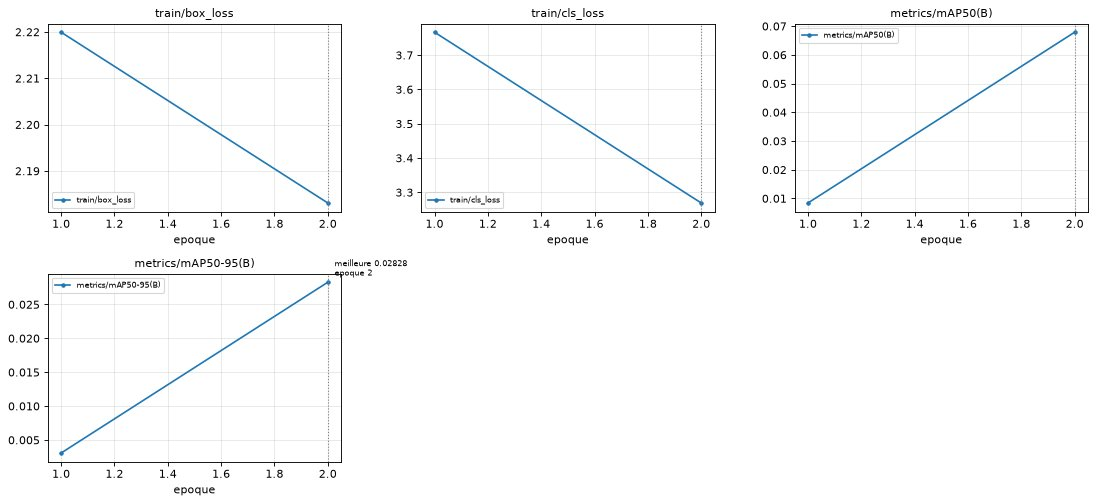

In [7]:
from ultralytics import YOLO  # YOLO : classe d'Ultralytics qui charge, entraine, evalue et exporte les modeles YOLO

start = time.perf_counter()  # chrono de l'entrainement
results = YOLO(WEIGHTS).train(  # charge les poids COCO puis entraine sur notre jeu ; renvoie un objet resultats
    data=str(data_yaml),  # description du jeu (data.yaml)
    epochs=EPOCHS,  # nombre maximal d'epoques
    imgsz=IMGSZ,  # taille d'entree du reseau
    batch=BATCH,  # images par lot
    patience=PATIENCE,  # arret anticipe
    close_mosaic=CLOSE_MOSAIC,  # dernieres epoques sans mosaic
    warmup_epochs=WARMUP_EPOCHS,  # epoques d'echauffement
    device=0 if DEVICE.type == "cuda" else "cpu",  # 0 = premiere carte graphique ; sinon processeur
    seed=SEED,  # graine : entrainement reproductible
    workers=0,  # images chargees dans le processus principal (plus sur sous Windows et dans un notebook)
    project=str((OUT / "runs").resolve()),  # chemin absolu, sinon Ultralytics prefixe runs/detect/
    name="train",  # sous-dossier de cet entrainement
    exist_ok=True,  # reecrit le dossier s'il existe deja
    plots=False,  # pas de graphiques Ultralytics (on trace les notres)
    verbose=False,  # sortie texte reduite
)
TRAIN_SECONDS = round(time.perf_counter() - start, 1)  # duree d'entrainement en secondes
shutil.copy2(Path(results.save_dir) / "weights" / "best.pt", OUT / "best.pt")  # copie le meilleur modele (best.pt) dans OUT
history = pd.read_csv(Path(results.save_dir) / "results.csv")  # historique par epoque ecrit par Ultralytics
history.columns = [c.strip() for c in history.columns]  # retire les espaces autour des noms de colonnes
print(f"entrainement : {TRAIN_SECONDS} s")  # duree
viz.plot_history(  # courbes d'entrainement, epoque par epoque
    history,  # le tableau lu ci-dessus
    # pertes d'entrainement (position des boites, classe) et mAP de validation
    metrics=["train/box_loss", "train/cls_loss", "metrics/mAP50(B)", "metrics/mAP50-95(B)"],
    best="metrics/mAP50-95(B):max",  # marque l'epoque au meilleur mAP50-95
)
plt.show()  # affiche la figure

## Etape 13 - Predire : par le chemin de production

Le modele recharge depuis `best.pt` (comme en production), puis pour chaque fichier : lecture
-> pretraitement -> 3 canaux BGR (Ultralytics suppose du BGR) -> modele (letterbox, NMS) ->
boites dans l'image pretraitee -> remise a l'echelle de l'image d'ORIGINE. C'est ce chemin
qu'on evalue : on mesure ce que verra la production, pas un raccourci.

Une prediction = un tableau `(n, 6)` : `x1, y1, x2, y2, score, classe`.

In [8]:
model = YOLO(str(OUT / "best.pt"))  # recharge le meilleur modele depuis le disque, comme en production


def predict_images(model, images, conf, imgsz=IMGSZ, iou=IOU_NMS):  # predit une liste d'images ; renvoie un tableau (n, 6) par image
    """Images pretraitees (gris ou RGB) -> (n, 6) dans le repere de ces images."""
    # Ultralytics fait letterbox, reseau et NMS ; images converties en BGR 3 canaux ; conf : seuil de confiance
    results = model.predict([to_bgr3(im) for im in images], imgsz=imgsz, conf=conf, iou=iou, verbose=False, device=DEVICE.type)
    return [  # une entree par image
        # colle cote a cote : coins (x1, y1, x2, y2), score de confiance, numero de classe ; .cpu().numpy() : tenseur -> numpy
        np.column_stack([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy()])
        .astype(np.float32)  # en float32
        .reshape(-1, 6)  # toujours la forme (n, 6), meme sans boite
        for r in results  # pour le resultat de chaque image
    ]


def predict_paths(model, paths, conf, batch_size=16):  # predit des fichiers ; renvoie un tableau (n, 6) par fichier, en pixels d'origine
    """Fichiers -> (n, 6) dans le repere de l'image d'ORIGINE."""
    out = []  # resultats, dans l'ordre des fichiers
    for start in range(0, len(paths), batch_size):  # par paquets de batch_size fichiers
        originals = [read_image(p, COLOR) for p in paths[start : start + batch_size]]  # lecture des images d'origine du paquet
        images = [preprocess(o) for o in originals]  # pretraitement (le meme qu'a l'entrainement)
        for original, image, rows in zip(originals, images, predict_images(model, images, conf)):  # chaque image et ses detections
            rows[:, [0, 2]] *= original.shape[1] / image.shape[1]  # x : repere pretraite -> repere d'origine (rapport des largeurs)
            rows[:, [1, 3]] *= original.shape[0] / image.shape[0]  # y : rapport des hauteurs
            out.append(rows)  # range les detections de cette image
    return out  # liste de tableaux (n, 6)


start = time.perf_counter()  # chrono de la prediction
val_preds = predict_paths(model, [r["path"] for r in subsets["val"]], CONF_EVAL)  # detections sur la validation (seuil tres bas)
test_preds = predict_paths(model, [r["path"] for r in subsets["test"]], CONF_EVAL)  # detections sur le test
MS_PER_IMAGE = round(1000 * (time.perf_counter() - start) / (len(val_preds) + len(test_preds)), 1)  # temps moyen par image, en ms
# temps par image, puis les 3 premieres detections de la premiere image de test (arrondies a 2 decimales)
print(f"{MS_PER_IMAGE} ms par image (pretraitement compris) ; exemple :\n", np.round(test_preds[0][:3], 2))

26.4 ms par image (pretraitement compris) ; exemple :
 [[       0.51         7.6      199.66      122.48        0.11           0]
 [      62.29        68.2      195.31      199.75        0.08           0]
 [      67.13        1.93       198.4      174.38        0.07           0]]


## Etape 11 - Evaluer : mAP COCO (toute la courbe) et point de fonctionnement (un seuil)

- mAP@0.5 : une detection est juste si son IoU avec une vraie boite de la meme classe atteint
  0,5 ; l'AP est l'aire sous la courbe precision-rappel, le mAP sa moyenne sur les classes.
  mAP@0.5:0.95 moyenne dix seuils d'IoU : il recompense les boites precises. On utilise
  pycocotools, la reference.
- Le point de fonctionnement : ce que l'operateur verra au seuil `conf` choisi. Appariement
  glouton par image et par classe (scores decroissants, IoU >= 0,5) -> vrais positifs, fausses
  alarmes, oublis ; plus deux chiffres "image" : la part des images avec defaut ou au moins un
  defaut est signale, et la part des images saines signalees a tort (NEU-DET n'a pas d'image
  saine : ce chiffre est vide ici).
- Le seuil se choisit sur la VALIDATION (ici : le meilleur F1), jamais sur le test.

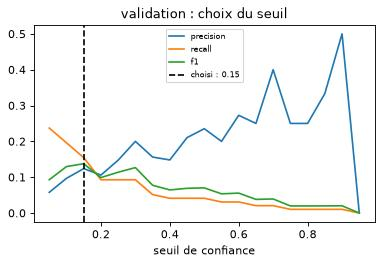

test : mAP50 0.130 | mAP50-95 0.052
seuil choisi sur la validation : 0.15 -> test {'tp': 16, 'fp': 83, 'fn': 68, 'precision': 0.1616, 'recall': 0.1905, 'f1': 0.1749} | rappel image 0.7778
seuil de la recette 0.25 -> test {'tp': 12, 'fp': 46, 'fn': 72, 'precision': 0.2069, 'recall': 0.1429, 'f1': 0.169}


,ap50,ap50_95,precision,recall
crazing,0.0285,0.0073,0.0455,0.0588
inclusion,0.1338,0.0424,0.1053,0.0833
patches,0.4469,0.2065,0.3810,0.4706
pitted_surface,0.0118,0.0056,0.0000,0.0000
rolled-in_scale,0.0000,0.0000,0.0000,0.0000
scratches,0.1607,0.0499,0.1613,0.5556


In [9]:
from pycocotools.coco import COCO  # COCO : verite terrain au format du concours COCO
from pycocotools.cocoeval import COCOeval  # COCOeval : calcule le mAP officiel COCO


def box_iou(a, b):  # IoU de deux boites (x1, y1, x2, y2) : aire commune / aire totale, entre 0 et 1
    # aire de l'intersection : largeur commune x hauteur commune (0 si les boites ne se touchent pas)
    inter = max(0.0, min(a[2], b[2]) - max(a[0], b[0])) * max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter  # aire de l'union : les deux aires moins l'intersection
    return float(inter / union) if union > 0 else 0.0  # IoU ; boites d'aire nulle : 0


def coco_metrics(items, preds, class_names):  # mAP et AP par classe (AP = aire sous la courbe precision-rappel) ; renvoie un dict
    """mAP@0.5, mAP@0.5:0.95 et AP par classe avec pycocotools (verite et predictions en pixels d'origine)."""
    index = {n: i for i, n in enumerate(class_names)}  # nom de classe -> numero
    images, annotations = [], []  # verite au format COCO : liste des images et liste des objets
    for image_id, record in enumerate(items):  # pour chaque image, numerotee a partir de 0
        images.append({"id": image_id, "width": record["width"], "height": record["height"]})  # description de l'image
        for (x1, y1, x2, y2), label in zip(record["boxes"], record["labels"]):  # pour chaque vraie boite et sa classe
            w, h = float(x2 - x1), float(y2 - y1)  # COCO decrit une boite par son coin haut-gauche, sa largeur et sa hauteur
            annotations.append(  # ajoute l'objet
                {  # un objet au format COCO
                    "id": len(annotations) + 1,  # numero unique de l'objet (a partir de 1)
                    "image_id": image_id,  # image a laquelle il appartient
                    "category_id": index[label],  # numero de sa classe
                    "bbox": [float(x1), float(y1), w, h],  # boite (x, y, largeur, hauteur)
                    "area": w * h,  # aire (sert a classer les objets en petits / moyens / grands)
                    "iscrowd": 0,  # objet individuel (pas une foule)
                }
            )
    results = [  # predictions au format COCO
        {  # une detection
            "image_id": i,  # image
            "category_id": int(r[5]),  # classe predite
            "bbox": [float(r[0]), float(r[1]), float(r[2] - r[0]), float(r[3] - r[1])],  # boite (x, y, largeur, hauteur)
            "score": float(r[4]),  # confiance
        }
        for i, rows in enumerate(preds)  # pour chaque image et ses detections
        for r in rows  # pour chaque detection de l'image
    ]
    if not results:  # aucune detection du tout (pycocotools refuserait une liste vide)
        return {"map50": 0.0, "map50_95": 0.0, "per_class": {n: {"ap50": 0.0, "ap50_95": 0.0} for n in class_names}}  # tout a zero
    with contextlib.redirect_stdout(io.StringIO()):  # pycocotools ecrit beaucoup
        truth = COCO()  # objet verite, vide
        truth.dataset = {  # rempli a la main
            "images": images,  # les images
            "annotations": annotations,  # les vrais objets
            "categories": [{"id": i, "name": n} for i, n in enumerate(class_names)],  # les classes
        }
        truth.createIndex()  # construit les index internes de pycocotools
        evaluator = COCOeval(truth, truth.loadRes(results), iouType="bbox")  # evaluation des boites : verite contre predictions
        evaluator.evaluate()  # appariements par image et par classe, pour 10 seuils d'IoU (0.5 a 0.95)
        evaluator.accumulate()  # construit les courbes precision-rappel
        evaluator.summarize()  # calcule les chiffres standards (stats) : stats[0] = mAP50-95, stats[1] = mAP50
    precision = evaluator.eval["precision"][:, :, :, 0, -1]  # (seuils IoU, rappel, classes), toutes tailles, 100 detections
    per_class = {}  # AP de chaque classe
    for k, class_id in enumerate(evaluator.params.catIds):  # pour chaque classe evaluee
        values = precision[:, :, k]  # ses precisions : seuils d'IoU x niveaux de rappel
        at50, valid = values[0][values[0] > -1], values[values > -1]  # IoU 0.5 seul, puis tous les seuils ; -1 = valeur absente
        per_class[class_names[class_id]] = {  # AP de la classe
            "ap50": round(float(at50.mean()), 4) if at50.size else 0.0,  # AP a IoU 0.5
            "ap50_95": round(float(valid.mean()), 4) if valid.size else 0.0,  # AP moyenne sur les 10 seuils d'IoU
        }
    return {"map50": float(evaluator.stats[1]), "map50_95": float(evaluator.stats[0]), "per_class": per_class}  # mAP globaux + detail


def operating_point(items, preds, class_names, conf, iou=0.5):  # bilan au seuil conf ; renvoie un dictionnaire de compteurs et de taux
    """Precision, rappel (objets) et decisions par image au seuil conf (appariement glouton)."""
    # par classe : vrais positifs (tp), faux positifs = fausses alarmes (fp), faux negatifs = oublis (fn)
    counts = {n: {"tp": 0, "fp": 0, "fn": 0} for n in class_names}
    flagged_defect = flagged_clean = n_defect = n_clean = 0  # compteurs au niveau image, tous a 0
    for record, rows in zip(items, preds):  # pour chaque image et ses detections
        kept = rows[rows[:, 4] >= conf]  # detections au-dessus du seuil
        if len(record["labels"]):  # image avec au moins un defaut
            n_defect, flagged_defect = n_defect + 1, flagged_defect + bool(len(kept))  # signalee si au moins une detection
        else:  # image saine
            n_clean, flagged_clean = n_clean + 1, flagged_clean + bool(len(kept))  # signalee a tort si au moins une detection
        for k, name in enumerate(class_names):  # pour chaque classe
            truth = [b for b, label in zip(record["boxes"], record["labels"]) if label == name]  # vraies boites de cette classe
            mine = kept[kept[:, 5] == k]  # detections de cette classe
            mine = mine[np.argsort(-mine[:, 4])]  # triees par score decroissant (appariement glouton : les plus sures d'abord)
            used = [False] * len(truth)  # chaque vraie boite deja appariee ou non
            for row in mine:  # pour chaque detection, de la plus sure a la moins sure
                scores = [box_iou(row[:4], t) if not used[j] else -1.0 for j, t in enumerate(truth)]  # IoU avec chaque vraie boite libre
                best = int(np.argmax(scores)) if scores else -1  # vraie boite la plus recouverte (-1 : aucune vraie boite)
                if best >= 0 and scores[best] >= iou:  # recouvrement suffisant (IoU >= 0.5)
                    used[best] = True  # cette vraie boite est prise
                    counts[name]["tp"] += 1  # vrai positif
                else:  # aucune vraie boite libre ne correspond
                    counts[name]["fp"] += 1  # fausse alarme
            counts[name]["fn"] += used.count(False)  # vraies boites jamais trouvees = oublis

    def rates(c):  # ajoute precision, rappel et F1 aux compteurs c ; renvoie un dictionnaire
        precision = c["tp"] / (c["tp"] + c["fp"]) if c["tp"] + c["fp"] else 0.0  # precision : part des detections qui sont justes
        recall = c["tp"] / (c["tp"] + c["fn"]) if c["tp"] + c["fn"] else 0.0  # rappel : part des vrais objets retrouves
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0  # F1 : compromis entre les deux (1 = parfait)
        return {**c, "precision": round(precision, 4), "recall": round(recall, 4), "f1": round(f1, 4)}  # compteurs + taux arrondis

    total = {k: sum(c[k] for c in counts.values()) for k in ("tp", "fp", "fn")}  # compteurs toutes classes confondues
    return {  # bilan au seuil conf
        "conf": conf,  # seuil utilise
        "overall": rates(total),  # toutes classes
        "per_class": {n: rates(c) for n, c in counts.items()},  # par classe
        "image_recall": round(flagged_defect / n_defect, 4) if n_defect else None,  # part des images avec defaut qui sont signalees
        "image_false_alarm_rate": round(flagged_clean / n_clean, 4) if n_clean else None,  # part des images saines signalees a tort
    }


def choose_conf(items, preds, class_names, grid=None):  # balaye le seuil de confiance ; renvoie (meilleur seuil, tableau)
    """Balayage du seuil sur la VALIDATION : precision, rappel, F1 ; on garde le meilleur F1."""
    grid = np.round(np.arange(0.05, 0.96, 0.05), 2) if grid is None else grid  # seuils essayes : 0.05, 0.10, ..., 0.95
    rows = [  # une ligne par seuil essaye
        # le seuil, puis precision, rappel et F1 toutes classes a ce seuil
        {"conf": c, **{k: operating_point(items, preds, class_names, c)["overall"][k] for k in ("precision", "recall", "f1")}}
        for c in grid  # pour chaque seuil de la grille
    ]
    table = pd.DataFrame(rows)  # tableau seuil -> precision, rappel, F1
    best = float(table.loc[table["f1"].idxmax(), "conf"]) if table["f1"].max() > 0 else CONF_PREDICT  # seuil au meilleur F1 (sinon recette)
    fig, ax = plt.subplots(figsize=(5.5, 3.2))  # une figure avec un graphique
    for column in ("precision", "recall", "f1"):  # pour chaque courbe
        ax.plot(table["conf"], table[column], label=column)  # courbe en fonction du seuil
    ax.axvline(best, color="k", linestyle="--", label=f"choisi : {best}")  # trait vertical au seuil choisi
    ax.set_xlabel("seuil de confiance")  # nom de l'axe horizontal
    ax.set_title("validation : choix du seuil")  # titre
    ax.legend(fontsize=7)  # legende
    plt.show()  # affiche
    return best, table  # seuil choisi et tableau du balayage


CHOSEN_CONF, sweep = choose_conf(subsets["val"], val_preds, CLASS_NAMES)  # seuil choisi sur la VALIDATION
test_metrics = coco_metrics(subsets["test"], test_preds, CLASS_NAMES)  # mAP du test (toute la courbe)
op_chosen = operating_point(subsets["test"], test_preds, CLASS_NAMES, CHOSEN_CONF)  # test au seuil choisi
op_recipe = operating_point(subsets["test"], test_preds, CLASS_NAMES, CONF_PREDICT)  # test au seuil de la recette, pour comparer
print(f"test : mAP50 {test_metrics['map50']:.3f} | mAP50-95 {test_metrics['map50_95']:.3f}")  # mAP du test
# resultats au seuil choisi, et part des images avec defaut signalees
print(f"seuil choisi sur la validation : {CHOSEN_CONF} -> test", op_chosen["overall"], "| rappel image", op_chosen["image_recall"])
print(f"seuil de la recette {CONF_PREDICT} -> test", op_recipe["overall"])  # resultats au seuil de la recette
# tableau par classe : AP (COCO), puis precision et rappel au seuil choisi
per_class = pd.DataFrame(test_metrics["per_class"]).T.join(pd.DataFrame(op_chosen["per_class"]).T[["precision", "recall"]])
display(per_class)  # affiche le tableau

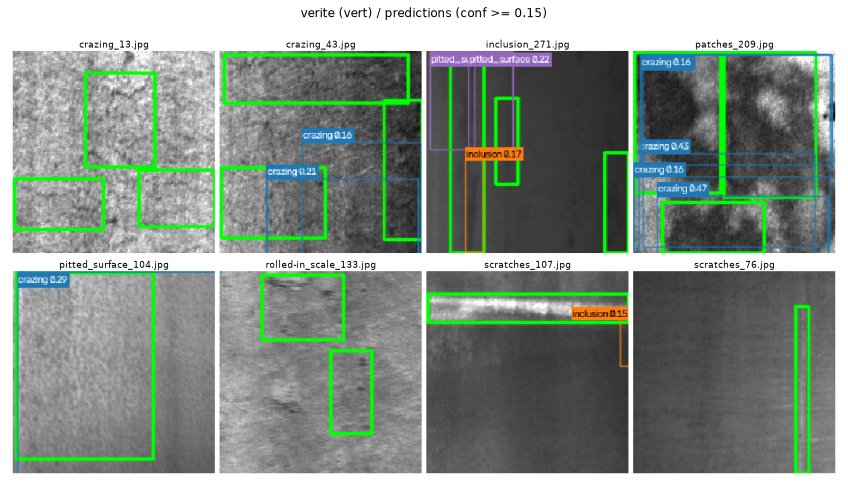

In [10]:
picked = [subsets["test"][i] for i in np.linspace(0, len(subsets["test"]) - 1, 8).astype(int)]  # 8 images de test reparties regulierement
pred_of = {r["path"]: p for r, p in zip(subsets["test"], test_preds)}  # chemin -> detections de l'image
gallery = []  # images dessinees
for r in picked:  # pour chaque image choisie
    rows = pred_of[r["path"]]  # ses detections (n, 6)
    gallery.append(  # ajoute l'image dessinee
        viz.draw_detections(  # dessine verite et predictions sur l'image
            read_image(r["path"], COLOR),  # l'image d'origine
            truth={"boxes": r["boxes"], "labels": [CLASS_INDEX[x] for x in r["labels"]]},  # verite : boites et numeros de classe
            pred={"boxes": rows[:, :4], "labels": rows[:, 5].astype(int), "scores": rows[:, 4]},  # predictions : boites, classes, scores
            class_names=CLASS_NAMES,  # noms des classes pour les etiquettes
            conf=CHOSEN_CONF,  # n'affiche que les predictions au-dessus du seuil choisi
        )
    )
viz.grid(  # planche des 8 images
    gallery,  # les images dessinees
    [Path(r["path"]).name for r in picked],  # titres : noms de fichier
    ncols=4,  # 4 colonnes
    size=2.6,  # taille de chaque case
    suptitle=f"verite (vert) / predictions (conf >= {CHOSEN_CONF})",  # titre general
)
plt.show()  # affiche la planche

## Etapes 12 et 13 - Exporter et predire : exporter en ONNX et ecrire le post-traitement

L'ONNX sort les predictions BRUTES, avant NMS : `(1, 4 + C, A)`, pour chaque ancre `cx, cy, w,
h` en pixels de l'image letterboxee puis un score par classe. Le programme de production (C#,
C++, Python sans PyTorch) fait le reste, ecrit ici en numpy :

1. letterbox CENTRE dans un carre `IMGSZ` (bordure grise 114), `/255`, NCHW ;
2. score max par ancre et sa classe, filtre `conf`, `cx, cy, w, h` -> coins ;
3. NMS par classe (deux classes ne s'eliminent pas) ;
4. retirer la bordure et diviser par le ratio -> repere de l'image pretraitee.

Deux verifications : sorties brutes ONNX == reseau PyTorch, et boites de la chaine ONNX +
numpy == boites de `model.predict` (IoU moyen >= 0,98, sinon l'export est refuse).

{'raw_max_abs_diff': 0.001953125, 'raw_scale': 483.2890625, 'boxes': 27, 'reference_boxes': 27, 'mean_iou': 1.0}


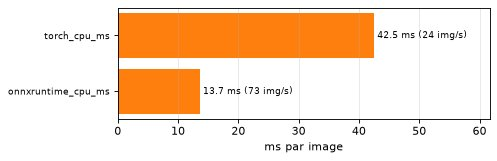

In [11]:
import onnx  # onnx : bibliotheque du format ONNX (ici pour noter sa version dans la carte)
import onnxruntime as ort  # onnxruntime : execute un modele ONNX sans PyTorch


def letterbox(image3, size, pad_value=114):  # letterbox : redimensionne sans deformer et complete par une bordure grise
    """Redimensionne sans deformer, centre dans un carre size x size ; rend (image, ratio, (pad_x, pad_y))."""
    height, width = image3.shape[:2]  # taille de l'image
    ratio = min(size / height, size / width)  # facteur d'echelle qui fait tenir le plus grand cote dans le carre
    new_w, new_h = round(width * ratio), round(height * ratio)  # nouvelle taille, proportions gardees
    pad_x, pad_y = (size - new_w) // 2, (size - new_h) // 2  # largeur de la bordure a gauche et en haut : l'image est centree
    canvas = np.full((size, size, 3), pad_value, dtype=image3.dtype)  # carre rempli de gris (114)
    # colle l'image redimensionnee au centre du carre
    canvas[pad_y : pad_y + new_h, pad_x : pad_x + new_w] = cv2.resize(image3, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    return canvas, ratio, (pad_x, pad_y)  # image, ratio et bordure (pour revenir ensuite aux coordonnees d'origine)


def to_input(image, size=IMGSZ):  # image pretraitee -> entree du reseau ONNX, plus ratio et bordure
    """Image pretraitee (gris ou RGB) -> tenseur (1, 3, S, S) float32 dans [0, 1], ratio, bordure."""
    boxed, ratio, pad = letterbox(to_three_channels(image), size)  # 3 canaux puis letterbox
    # (H, W, C) -> (C, H, W), [None] ajoute l'axe du lot (NCHW) ; / 255 : pixels dans [0, 1] ; contiguous : memoire d'un bloc
    return np.ascontiguousarray(boxed.astype(np.float32).transpose(2, 0, 1)[None] / 255.0), ratio, pad


def nms(boxes, scores, iou):  # NMS sur des boites (n, 4) ; renvoie les numeros des boites gardees
    """Suppression des non-maxima : garder la meilleure boite, retirer celles qui la recouvrent trop, recommencer."""
    order, keep = np.argsort(-scores), []  # numeros des boites par score decroissant ; liste des boites gardees
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])  # aire de chaque boite
    while len(order):  # tant qu'il reste des boites a examiner
        i, rest = order[0], order[1:]  # la meilleure restante, et les autres
        keep.append(i)  # on la garde
        xx1, yy1 = np.maximum(boxes[i, 0], boxes[rest, 0]), np.maximum(boxes[i, 1], boxes[rest, 1])  # coin haut-gauche des intersections
        xx2, yy2 = np.minimum(boxes[i, 2], boxes[rest, 2]), np.minimum(boxes[i, 3], boxes[rest, 3])  # coin bas-droite des intersections
        inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)  # aire d'intersection (0 si pas de chevauchement)
        # garde seulement les boites dont l'IoU avec la meilleure est <= iou ; les autres sont des doublons
        order = rest[inter / (areas[i] + areas[rest] - inter + 1e-9) <= iou]
    return np.array(keep, dtype=np.int64)  # numeros des boites gardees


def nms_per_class(rows, iou):  # NMS classe par classe sur des lignes (n, 6) ; renvoie les lignes gardees, par score decroissant
    # pour chaque classe presente : ses lignes, filtrees par la NMS (deux classes differentes ne s'eliminent pas)
    kept = [rows[rows[:, 5] == c][nms(rows[rows[:, 5] == c, :4], rows[rows[:, 5] == c, 4], iou)] for c in np.unique(rows[:, 5])]
    out = np.concatenate(kept) if kept else np.zeros((0, 6), np.float32)  # recolle les classes ; aucune : tableau vide (0, 6)
    return out[np.argsort(-out[:, 4])]  # trie par score decroissant


def postprocess_yolo(output, ratio, pad, conf, iou, shape):  # sortie brute du reseau -> detections (n, 6)
    """Sortie brute (1, 4 + C, A) -> (n, 6) dans l'image donnee au letterbox (hauteur, largeur = shape)."""
    pred = output[0].T  # premiere image du lot, transposee : (A, 4 + C), une ligne par ancre (position candidate d'un objet)
    scores, classes = pred[:, 4:].max(axis=1), pred[:, 4:].argmax(axis=1)  # meilleur score de classe de chaque ancre, et cette classe
    keep = scores > conf  # ancres au-dessus du seuil de confiance
    pred, scores, classes = pred[keep], scores[keep], classes[keep]  # on ne garde qu'elles
    if len(pred) == 0:  # aucune ancre retenue
        return np.zeros((0, 6), np.float32)  # aucune detection
    cx, cy, w, h = pred[:, 0], pred[:, 1], pred[:, 2], pred[:, 3]  # centre, largeur et hauteur de chaque boite (pixels letterbox)
    # coins (x1, y1, x2, y2) = centre -/+ demi-taille ; puis colonnes score et classe ; puis NMS par classe
    rows = nms_per_class(np.column_stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2, scores, classes]).astype(np.float32), iou)
    # x : retire la bordure, divise par le ratio, borne a la largeur
    rows[:, [0, 2]] = ((rows[:, [0, 2]] - pad[0]) / ratio).clip(0, shape[1])
    rows[:, [1, 3]] = ((rows[:, [1, 3]] - pad[1]) / ratio).clip(0, shape[0])  # y : idem, borne a la hauteur
    return rows  # detections dans le repere de l'image pretraitee


def mean_best_iou(mine, reference):  # compare deux listes de detections ; renvoie nombres de boites et IoU moyen
    """Pour chaque boite de `mine`, IoU avec la plus proche de `reference` (meme image) ; un ecart de nombre est un bug."""
    ious = []  # meilleur IoU de chacune de nos boites
    for rows, ref in zip(mine, reference):  # pour chaque image : nos boites et celles de reference
        for row in rows:  # pour chacune de nos boites
            if len(ref):  # si l'image a des boites de reference
                # meilleur accord avec une boite de reference ; boite identique (coins a 0.5 px pres) = accord parfait, meme d'aire nulle
                ious.append(max(1.0 if np.allclose(row[:4], r[:4], atol=0.5) else box_iou(row[:4], r[:4]) for r in ref))
    return {  # bilan
        "boxes": int(sum(len(m) for m in mine)),  # nombre de nos boites
        "reference_boxes": int(sum(len(r) for r in reference)),  # nombre de boites de reference
        "mean_iou": float(np.mean(ious)) if ious else None,  # IoU moyen (None si aucune boite)
    }


# export ONNX par Ultralytics : lot dynamique, sans NMS (on l'ecrit nous-memes), sur CPU ; renvoie le chemin du fichier cree
exported = Path(model.export(format="onnx", imgsz=IMGSZ, dynamic=True, nms=False, simplify=False, opset=OPSET, device="cpu"))
onnx_path = OUT / "model.onnx"  # emplacement final du modele
shutil.move(str(exported), onnx_path)  # deplace le fichier exporte dans OUT
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge le modele ONNX, execution sur CPU
input_name = session.get_inputs()[0].name  # nom de l'entree du reseau (a donner a session.run)

samples = [preprocess(read_image(r["path"], COLOR)) for r in subsets["val"][:4]]  # 4 images de validation, pretraitees
net = model.model.eval().float()  # le reseau PyTorch d'Ultralytics, en mode evaluation et en float32
raw_gap, raw_scale, mine, reference = 0.0, 1.0, [], []  # plus grand ecart, plus grande sortie, detections ONNX + numpy, Ultralytics
for image in samples:  # pour chaque image
    tensor, ratio, pad = to_input(image)  # entree du reseau (letterbox, / 255, NCHW)
    onnx_out = session.run(None, {input_name: tensor})[0]  # sortie brute ONNX (None = toutes les sorties ; [0] = la premiere)
    with torch.no_grad():  # sans gradient (calcul utile seulement pour apprendre) : plus rapide
        torch_out = net(torch.from_numpy(tensor))  # sortie brute PyTorch pour la meme entree
    while isinstance(torch_out, (list, tuple)):  # detect rend (sortie, details) en mode eval
        torch_out = torch_out[0]  # on garde la sortie principale
    raw_gap = max(raw_gap, float(np.abs(torch_out.numpy() - onnx_out).max()))  # plus grand ecart ONNX / PyTorch
    raw_scale = max(raw_scale, float(np.abs(torch_out.numpy()).max()))  # plus grande valeur de sortie (pour une tolerance relative)
    mine.append(postprocess_yolo(onnx_out, ratio, pad, VERIFY_CONF, IOU_NMS, image.shape[:2]))  # detections : notre chaine ONNX + numpy
    reference.append(predict_images(model, [image], VERIFY_CONF)[0])  # detections d'Ultralytics, au meme seuil
EXPORT_CHECK = {"raw_max_abs_diff": raw_gap, "raw_scale": raw_scale, **mean_best_iou(mine, reference)}  # bilan de la verification
print(EXPORT_CHECK)  # affiche le bilan
assert raw_gap <= 1e-4 + 1e-3 * raw_scale * 10, "sorties brutes ONNX differentes de PyTorch"  # ecart trop grand : arret
# IoU moyen < 0.98 : notre post-traitement ne reproduit pas Ultralytics, arret (None : aucune boite a comparer)
assert EXPORT_CHECK["mean_iou"] is None or EXPORT_CHECK["mean_iou"] >= 0.98, "le post-traitement ne reproduit pas Ultralytics"


def timed(fn, runs=20):  # mesure la duree moyenne d'un appel a fn ; renvoie des millisecondes
    for _ in range(3):  # 3 appels d'echauffement, non chronometres
        fn()  # les premiers appels sont toujours plus lents
    start = time.perf_counter()  # chrono precis
    for _ in range(runs):  # appels chronometres
        fn()  # un appel
    return round(1000 * (time.perf_counter() - start) / runs, 2)  # moyenne en ms par appel


x = to_input(samples[0])[0]  # une entree (1, 3, IMGSZ, IMGSZ) ; [0] : le tenseur seul, sans ratio ni bordure
with torch.no_grad():  # sans gradient
    LATENCY = {  # latence (temps de reponse) par moteur, en ms par image
        "torch_cpu_ms": timed(lambda: net(torch.from_numpy(x))),  # reseau PyTorch
        "onnxruntime_cpu_ms": timed(lambda: session.run(None, {input_name: x})),  # modele ONNX avec onnxruntime
    }
viz.latency_bars(LATENCY)  # barres de latence (et images par seconde)
plt.show()  # affiche

## Etape 12 - Sauvegarder et exporter : la carte du modele

`model_card.json` dit au programme de production tout ce qu'il faut : couleur de lecture,
pretraitement, taille et mise a l'echelle de l'entree, sorties, classes, seuils (celui choisi
sur la validation), post-traitement, metriques, latence. Meme format que `vtb.export.card` :
le service `vtb.serve` et le programme C# servent ce dossier sans rien changer.

In [12]:
def framework_versions():  # renvoie les versions des logiciels utilises (notees dans la carte)
    # versions de Python, PyTorch, onnx et onnxruntime : utiles pour reproduire ou diagnostiquer un ecart
    return {"python": platform.python_version(), "torch": torch.__version__, "onnx": onnx.__version__, "onnxruntime": ort.__version__}


def write_card(card, folder):  # complete la carte et l'ecrit dans folder/model_card.json ; renvoie la carte complete
    card = {"created_utc": datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ"), "framework": framework_versions(), **card}  # date + versions
    (Path(folder) / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit en JSON lisible (indentation 2)
    return card  # la carte complete


card = write_card(  # ecrit la carte du modele dans OUT
    {  # contenu de la carte
        "task": "detection",  # type de tache
        "model_name": f"ultralytics:{Path(WEIGHTS).stem}",  # le prefixe choisit le decodeur en production
        "input": {  # description de l'entree du reseau
            "name": input_name,  # nom de l'entree ONNX
            "layout": "NCHW",  # ordre des axes : lot (N), canaux (C), hauteur (H), largeur (W)
            "height": IMGSZ,  # hauteur
            "width": IMGSZ,  # largeur
            "channels": 3,  # nombre de canaux
            "color": "RGB",  # ordre des canaux attendu par le reseau
            "dtype": "float32",  # type des nombres
            "scale": "divide by 255",  # pixels divises par 255 : dans [0, 1]
            "mean": [],  # pas de normalisation par une moyenne...
            "std": [],  # ... ni par un ecart-type (YOLO n'en utilise pas)
            "resize": "letterbox",  # redimensionnement sans deformation + bordure
            "letterbox_pad_value": 114,  # gris de la bordure
            # lot dynamique si la 1re dimension est un nom, pas un nombre
            "dynamic_batch": isinstance(session.get_inputs()[0].shape[0], str),
            "read_color": COLOR,  # couleur de lecture du fichier, avant le pretraitement
        },
        "preprocess": PREPROCESS,  # operations de pretraitement a rejouer
        "outputs": [  # description des sorties du reseau
            # nom et forme de chaque sortie ONNX
            {"name": o.name, "shape": list(o.shape), "description": "sortie brute YOLO11 (avant NMS)"}
            for o in session.get_outputs()  # pour chaque sortie du modele ONNX
        ],
        "class_names": CLASS_NAMES,  # classes, dans l'ordre de leurs numeros
        "thresholds": {"conf": CHOSEN_CONF, "iou_nms": IOU_NMS},  # seuil de confiance choisi sur la validation, seuil de la NMS
        "postprocess": {  # post-traitement que la production doit refaire
            "steps": (  # les etapes, en clair
                "letterbox centre gris 114 -> /255 -> reseau -> transposer (A, 4 + C) -> score max par ancre -> filtre conf"
                " -> cx,cy,w,h -> coins -> NMS par classe -> retirer la bordure et diviser par le ratio"
            ),
            # ou trouver une implementation de reference
            "reference": "notebooks/08_detection_yolo (postprocess_yolo) ; vtb.tasks.detection.ultralytics_backend.postprocess_detect",
        },
        "metrics": {  # metriques du test
            "map50": test_metrics["map50"],  # mAP a IoU 0.5
            "map50_95": test_metrics["map50_95"],  # mAP moyenne sur les IoU 0.5 a 0.95
            "n_images": len(subsets["test"]),  # nombre d'images de test
            "operating_point": op_chosen["overall"],  # precision, rappel, F1 au seuil choisi
        },
        "latency_ms": LATENCY,  # latences mesurees
        "files": {"onnx": "model.onnx"},  # nom du fichier du modele
        "notes": f"notebook 08 ; verification ONNX : {EXPORT_CHECK}",  # resultat de la verification d'export
    },
    OUT,  # dossier ou ecrire la carte
)
print(json.dumps(card["input"], indent=1))  # affiche la description de l'entree

{
 "name": "images",
 "layout": "NCHW",
 "height": 320,
 "width": 320,
 "channels": 3,
 "color": "RGB",
 "dtype": "float32",
 "scale": "divide by 255",
 "mean": [],
 "std": [],
 "resize": "letterbox",
 "letterbox_pad_value": 114,
 "dynamic_batch": true,
 "read_color": "gray"
}


## Variante (etapes 3 a 11) : boites orientees (OBB) et segmentation d'instances depuis des masques

Le meme fil, refait en court sur un autre jeu : cataloguer (3), decouper (4), ecrire le jeu (5),
entrainer (6 a 10), evaluer (11).

Une fissure fine et en biais tient mal dans une boite droite (la boite est surtout du fond).
Deux reponses sans changer de moteur :

- **OBB** : une boite orientee `(cx, cy, w, h, angle)` par objet = `cv2.minAreaRect` de chaque
  composante connexe du masque ; format YOLO `classe x1 y1 x2 y2 x3 y3 x4 y4` (4 coins) ;
- **instances** : un polygone par objet = contour (`cv2.findContours`) simplifie
  (`cv2.approxPolyDP`, epsilon 1 px) ; format YOLO `classe x1 y1 ... xn yn`.

Magnetic Tile fournit un masque binaire par image ; la classe est le dossier (`MT_Crack`...),
les images de `MT_Free` n'ont aucun objet (elles apprennent au detecteur a se taire). Essai d'une
epoque : il verifie la chaine, pas la precision.

In [13]:
def mask_objects(mask_path, kind, min_area=20, epsilon=1.0):  # masque -> objets ; kind = "rotated" (boites orientees) ou "polygons"
    """Masque binaire -> boites orientees (cx, cy, w, h, angle) ou polygones (k, 2), un objet par composante."""
    binary = (read_image(mask_path, "gray") > 127).astype(np.uint8)  # seuil 127 : ignore les bords anti-creneles
    if kind == "rotated":  # boites orientees demandees
        out = []  # une boite (cx, cy, w, h, angle) par objet
        # composantes connexes : groupes de pixels blancs qui se touchent (8 voisins) ; stats donne l'aire de chacune
        count, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
        for k in range(1, count):  # pour chaque composante (la 0 est le fond)
            if stats[k, cv2.CC_STAT_AREA] >= min_area:  # assez grande (sinon c'est du bruit)
                ys, xs = np.nonzero(labels == k)  # coordonnees des pixels de cette composante
                points = np.stack([xs, ys], axis=1).astype(np.float32)  # points (x, y)
                # un pixel (x, y) couvre le carre [x, x + 1] : sans cela un objet d'un pixel de large serait plat
                corners = np.concatenate([points, points + (1, 0), points + (0, 1), points + (1, 1)]).astype(np.float32)
                (cx, cy), (w, h), angle = cv2.minAreaRect(corners)  # plus petit rectangle tourne contenant tous ces coins
                out.append((cx, cy, w, h, angle))  # centre, taille et angle (en degres)
        return out  # les boites orientees
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)  # contours exterieurs des objets
    # chaque contour assez grand, simplifie (ecart max epsilon px), mis en tableau (k, 2) de points (x, y)
    polygons = [cv2.approxPolyDP(c, epsilon, True).reshape(-1, 2).astype(np.float32) for c in contours if cv2.contourArea(c) >= min_area]
    return [p for p in polygons if len(p) >= 3]  # un polygone a au moins 3 points


tile_paths = sorted(p for p in TILE_DIR.rglob("*.jpg"))  # les masques .png sont a cote : on ne liste que les .jpg
tile_records = []  # un enregistrement par image Magnetic Tile
for image_path in tile_paths:  # pour chaque image
    folder = image_path.relative_to(TILE_DIR).parts[0]  # premier dossier du chemin = la classe (MT_Crack...)
    mask_path = image_path.with_suffix(".png")  # son masque : meme nom, extension .png
    height, width = read_image(mask_path, "gray").shape  # taille de l'image (lue sur le masque)
    rotated = mask_objects(mask_path, "rotated")  # boites orientees des objets
    polygons = mask_objects(mask_path, "polygons")  # polygones des objets
    tile_records.append(  # range l'enregistrement
        {  # meme structure que pour NEU-DET, plus les boites orientees et les polygones
            "path": str(image_path),  # chemin de l'image
            "width": width,  # largeur
            "height": height,  # hauteur
            "rotated": rotated,  # boites orientees
            "polygons": polygons,  # polygones
            "folder": folder,  # classe (nom du dossier)
            "labels": [folder] * len(rotated),  # une etiquette par objet ; image MT_Free : aucun objet
        }
    )
TILE_CLASS_NAMES = sorted({r["folder"] for r in tile_records if r["labels"]})  # classes = dossiers ayant des objets (MT_Free exclu)
tile_by_path = {r["path"]: r for r in tile_records}  # chemin -> enregistrement
tile_catalog = pd.DataFrame(  # catalogue : une ligne par image
    [  # construit par comprehension
        # chemin, classe principale (ou "background"), nombre d'objets, taille
        {"path": r["path"], "label": main_label(r["labels"]), "n_objects": len(r["labels"]), "width": r["width"], "height": r["height"]}
        for r in tile_records  # pour chaque image
    ]
)
if TILE_MAX_IMAGES is not None and len(tile_catalog) > TILE_MAX_IMAGES:  # mode rapide : plus d'images que voulu
    # sous-echantillon fixe (graine 0), trie par chemin
    tile_catalog = tile_catalog.sample(n=TILE_MAX_IMAGES, random_state=0).sort_values("path").reset_index(drop=True)
grouped = not QUICK and TILE_GROUPS_CSV.exists()  # configuration complete : quasi-doublons du meme cote
if grouped:  # groupes de quasi-doublons disponibles
    groups = pd.read_csv(TILE_GROUPS_CSV, keep_default_na=False).set_index("path")["group"].astype(str)  # chemin -> groupe
    tile_catalog["group"] = [groups.get(p, p) for p in tile_catalog["path"]]  # groupe de chaque image (inconnue : son propre groupe)
else:  # pas de groupes
    tile_catalog["group"] = tile_catalog["path"]  # chaque image est son propre groupe
tile_split = make_split(tile_catalog, 0.15, 0.2, SEED, grouped=grouped)  # decoupage : 15 % validation, 20 % test
tile_split.to_csv(OUT / "tile_split.csv", index=False)  # ecrit le decoupage
compare_to_recipe(tile_split, RECIPE_TILE_SPLIT)  # compare a la recette si elle a tourne
# enregistrements complets de chaque sous-ensemble
tile_subsets = {s: [tile_by_path[p] for p in tile_split.loc[tile_split["split"] == s, "path"]] for s in ("train", "val", "test")}
print(TILE_CLASS_NAMES, {s: len(v) for s, v in tile_subsets.items()})  # classes et nombre d'images par sous-ensemble

decoupage identique a celui de la recette (outputs/detection/quick_tile_split.csv) : True
['MT_Blowhole', 'MT_Break', 'MT_Crack', 'MT_Fray', 'MT_Uneven'] {'train': 130, 'val': 30, 'test': 40}


In [14]:
TILE_INDEX = {n: i for i, n in enumerate(TILE_CLASS_NAMES)}  # classe -> numero


def obb_lines(record):  # boites orientees d'une image -> lignes au format YOLO OBB ; renvoie une liste de lignes
    """Une ligne par boite orientee : classe + 4 coins normalises (ordre de cv2.boxPoints)."""
    lines = []  # une ligne par objet
    for cx, cy, w, h, angle in record["rotated"]:  # pour chaque boite orientee
        corners = cv2.boxPoints(((cx, cy), (w, h), angle)) / [record["width"], record["height"]]  # ses 4 coins, divises par la taille
        # "classe x1 y1 x2 y2 x3 y3 x4 y4", coins bornes a [0, 1]
        lines.append(f"{TILE_INDEX[record['folder']]} " + " ".join(f"{v:.6f}" for v in np.clip(corners.ravel(), 0, 1)))
    return lines  # les lignes du fichier .txt


def segment_lines(record):  # polygones d'une image -> lignes au format YOLO segmentation ; renvoie une liste de lignes
    """Une ligne par polygone : classe + points normalises."""
    lines = []  # une ligne par objet
    for polygon in record["polygons"]:  # pour chaque polygone
        coords = np.clip((polygon / [record["width"], record["height"]]).ravel(), 0, 1)  # points normalises, aplatis (x1, y1, x2, y2...)
        lines.append(f"{TILE_INDEX[record['folder']]} " + " ".join(f"{v:.6f}" for v in coords))  # "classe x1 y1 ... xn yn"
    return lines  # les lignes du fichier .txt


def train_ultralytics(weights, data_yaml, name, imgsz):  # entraine puis evalue sur le test ; renvoie (modele, scores)
    results = YOLO(weights).train(  # entrainement a partir des poids donnes (OBB ou segmentation)
        data=str(data_yaml),  # description du jeu
        epochs=TILE_EPOCHS,  # nombre d'epoques
        imgsz=imgsz,  # taille d'entree
        batch=BATCH,  # images par lot
        patience=TILE_EPOCHS if QUICK else 20,  # arret anticipe (mode rapide : jamais avant la fin)
        device=0 if DEVICE.type == "cuda" else "cpu",  # premiere carte graphique, sinon processeur
        seed=SEED,  # graine : resultat reproductible
        workers=0,  # images chargees dans le processus principal
        project=str((OUT / "runs").resolve()),  # dossier des entrainements (chemin absolu)
        name=name,  # sous-dossier de cet entrainement
        exist_ok=True,  # reecrit le dossier s'il existe
        plots=False,  # pas de graphiques Ultralytics
        verbose=False,  # sortie texte reduite
    )
    tuned = YOLO(str(Path(results.save_dir) / "weights" / "best.pt"))  # recharge le meilleur modele
    metrics = tuned.val(  # evaluation sur le TEST
        data=str(data_yaml),  # description du jeu
        split="test",  # sous-ensemble evalue
        imgsz=imgsz,  # taille d'entree
        batch=BATCH,  # images par lot
        conf=CONF_EVAL,  # seuil tres bas : toute la courbe precision-rappel
        iou=IOU_NMS,  # seuil de la NMS
        device=DEVICE.type,  # "cuda" ou "cpu"
        project=str((OUT / "runs").resolve()),  # dossier des resultats
        name=f"{name}_test",  # sous-dossier de cette evaluation
        exist_ok=True,  # reecrit le dossier s'il existe
        plots=False,  # pas de graphiques
        verbose=False,  # sortie texte reduite
    )
    scores = {"box_map50": round(float(metrics.box.map50), 4), "box_map50_95": round(float(metrics.box.map), 4)}  # mAP des boites
    if getattr(metrics, "seg", None) is not None and name == "segment":  # modele de segmentation : il a aussi des scores de masques
        scores.update({"mask_map50": round(float(metrics.seg.map50), 4), "mask_map50_95": round(float(metrics.seg.map), 4)})  # mAP masques
    return tuned, scores  # modele entraine et ses scores


start = time.perf_counter()  # chrono des deux entrainements
obb_model, obb_scores = train_ultralytics(  # modele de boites orientees (OBB)
    "weights/yolo11n-obb.pt",  # poids OBB pre-entraines
    write_yolo_dataset(tile_subsets, OUT / "obb_dataset", obb_lines, TILE_CLASS_NAMES),  # ecrit le jeu au format OBB, renvoie data.yaml
    "obb",  # nom de l'essai
    TILE_IMGSZ,  # taille d'entree
)
seg_model, seg_scores = train_ultralytics(  # modele de segmentation d'instances (un contour par objet)
    "weights/yolo11n-seg.pt",  # poids de segmentation pre-entraines
    write_yolo_dataset(tile_subsets, OUT / "seg_dataset", segment_lines, TILE_CLASS_NAMES),  # jeu au format segmentation, renvoie data.yaml
    "segment",  # nom de l'essai (sert aussi a lire les scores de masques)
    TILE_IMGSZ,  # taille d'entree
)
TILE_SECONDS = round(time.perf_counter() - start, 1)  # duree des deux entrainements en secondes
print(f"{TILE_SECONDS} s ; OBB :", obb_scores, "| instances :", seg_scores)  # duree et scores

36.9 s ; OBB : {'box_map50': 0.0625, 'box_map50_95': 0.0063} | instances : {'box_map50': 0.0, 'box_map50_95': 0.0, 'mask_map50': 0.0, 'mask_map50_95': 0.0}


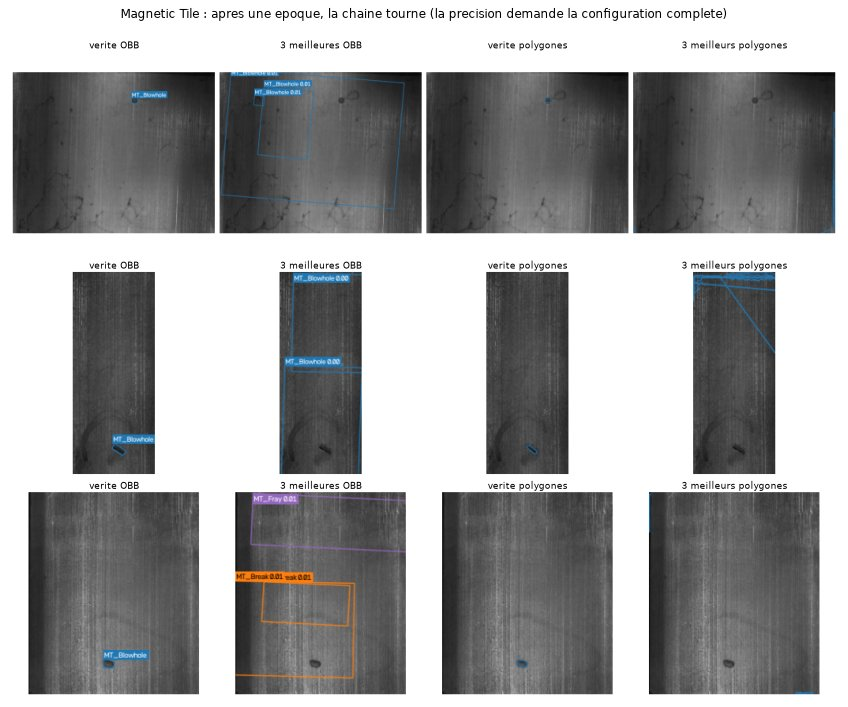

In [15]:
tile_show = [r for r in tile_subsets["test"] if r["labels"]][:3]  # 3 images de test qui ont au moins un defaut
panels, titles = [], []  # images dessinees et leurs titres
for r in tile_show:  # pour chaque image
    image = read_image(r["path"], COLOR)  # lecture
    # boites orientees predites ([0] : la seule image ; .obb : ses boites orientees)
    obb = obb_model.predict(to_bgr3(image), imgsz=TILE_IMGSZ, conf=CONF_EVAL, verbose=False, device=DEVICE.type)[0].obb
    seg = seg_model.predict(to_bgr3(image), imgsz=TILE_IMGSZ, conf=CONF_EVAL, verbose=False, device=DEVICE.type)[0]  # segmentation predite
    # vraies boites orientees (n, 5)
    truth_rot = np.array([[cx, cy, w, h, a] for cx, cy, w, h, a in r["rotated"]], np.float32).reshape(-1, 5)
    # predictions (cx, cy, w, h, angle) : Ultralytics donne l'angle en radians, le dessin attend des degres
    pred_rot = np.column_stack([obb.xywhr.cpu().numpy()[:, :4], np.degrees(obb.xywhr.cpu().numpy()[:, 4])]).reshape(-1, 5)
    pred_polys = [p for p in (seg.masks.xy if seg.masks is not None else []) if len(p) >= 3]  # contours des masques predits (>= 3 points)
    panels += [  # 4 images par exemple
        # verite : boites orientees avec leur classe
        viz.draw_boxes(image, truth_rot, rotated=True, labels=[TILE_INDEX[r["folder"]]] * len(truth_rot), class_names=TILE_CLASS_NAMES),
        viz.draw_boxes(  # predictions : les 3 meilleures boites orientees
            image,  # l'image
            pred_rot[:3],  # 3 premieres boites (les plus sures)
            rotated=True,  # boites orientees
            scores=obb.conf.cpu().numpy()[:3],  # leurs scores
            labels=obb.cls.cpu().numpy().astype(int)[:3],  # leurs classes
            class_names=TILE_CLASS_NAMES,  # noms des classes
        ),
        viz.draw_boxes(image, np.zeros((0, 4)), polygons=r["polygons"]),  # verite : polygones (aucune boite)
        viz.draw_boxes(image, np.zeros((0, 4)), polygons=pred_polys[:3]),  # predictions : 3 meilleurs polygones
    ]
    titles += ["verite OBB", "3 meilleures OBB", "verite polygones", "3 meilleurs polygones"]  # titres des 4 images
viz.grid(  # planche
    panels,  # les images dessinees
    titles,  # leurs titres
    ncols=4,  # 4 colonnes
    size=2.6,  # taille de chaque case
    suptitle="Magnetic Tile : apres une epoque, la chaine tourne (la precision demande la configuration complete)",  # titre general
)
plt.show()  # affiche la planche

## Etape 13 - Predire : inference par tuiles sur une grande image

Une bande d'acier en camera lineaire fait des milliers de pixels : la reduire a `IMGSZ` ecrase
les petits defauts. On la decoupe en tuiles A L'ECHELLE de l'entrainement (ici 200 px, la
taille des images NEU-DET), avec recouvrement pour qu'un defaut coupe par un bord apparaisse
entier dans une tuile voisine ; on predit chaque tuile, on ramene les boites dans l'image
complete (decalage de la tuile) et une NMS par classe fusionne les doublons des recouvrements.

Demonstration : une "grande image" composee de 2 x 3 images de test (400 x 600 px).

image entiere  {'tp': 0, 'fp': 5, 'fn': 15, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
par tuiles     {'tp': 0, 'fp': 15, 'fn': 15, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


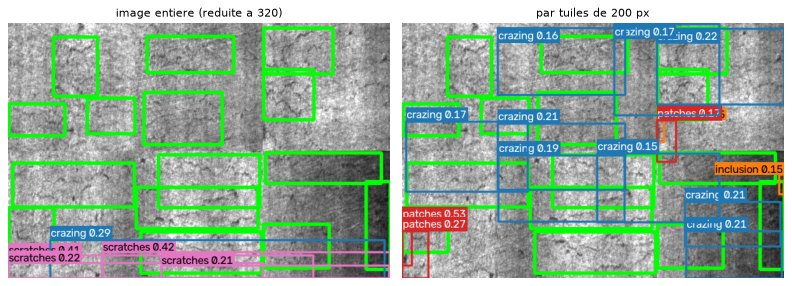

In [16]:
def tile_starts(length, size, step):  # positions de depart des tuiles le long d'un axe ; renvoie une liste
    """Positions de depart le long d'un axe ; la derniere tuile est collee au bord (pas de tuile partielle)."""
    if length <= size:  # l'axe tient dans une seule tuile
        return [0]  # une seule tuile, au debut
    starts = list(range(0, length - size + 1, step))  # departs espaces de step, sans que la tuile depasse le bord
    return starts if starts[-1] == length - size else starts + [length - size]  # ajoute une tuile collee au bord si besoin


def predict_tiled(predict_one, image, tile=200, overlap=0.25, iou_merge=0.5):  # predit par tuiles ; renvoie (n, 6) dans l'image complete
    step = tile - int(round(overlap * tile))  # pas entre deux tuiles : 25 % de recouvrement
    rows = []  # detections de chaque tuile
    for y in tile_starts(image.shape[0], tile, step):  # pour chaque position verticale
        for x in tile_starts(image.shape[1], tile, step):  # pour chaque position horizontale
            found = predict_one(image[y : y + tile, x : x + tile]).copy()  # predit sur la tuile (copie : on va la modifier)
            found[:, [0, 2]] += x  # x : repere de la tuile -> repere de l'image complete
            found[:, [1, 3]] += y  # y : idem
            rows.append(found)  # garde ces detections
    merged = np.concatenate(rows) if rows else np.zeros((0, 6), np.float32)  # toutes les detections ensemble
    return nms_per_class(merged, iou_merge) if len(merged) else merged  # NMS par classe : fusionne les doublons des recouvrements


parts = subsets["test"][:6]  # 6 images de test
# grande image : 2 rangees (vstack, empilees verticalement) de 3 images collees cote a cote (hstack)
big = np.vstack([np.hstack([read_image(r["path"], COLOR) for r in parts[row * 3 : row * 3 + 3]]) for row in range(2)])
big_truth = {"boxes": [], "labels": []}  # verite de la grande image
for k, r in enumerate(parts):  # pour chaque petite image et sa position k (0 a 5)
    dy, dx = (k // 3) * 200, (k % 3) * 200  # decalage de la petite image dans la grande (200 px = taille d'une image NEU-DET)
    big_truth["boxes"] += [[b[0] + dx, b[1] + dy, b[2] + dx, b[3] + dy] for b in r["boxes"]]  # ses boites, decalees
    big_truth["labels"] += [CLASS_INDEX[x] for x in r["labels"]]  # leurs classes, en numeros
big_record = {  # enregistrement au format habituel, pour operating_point
    "width": big.shape[1],  # largeur
    "height": big.shape[0],  # hauteur
    "boxes": np.array(big_truth["boxes"], np.float32),  # boites (n, 4)
    "labels": [CLASS_NAMES[i] for i in big_truth["labels"]],  # classes, en noms
}
whole = predict_images(model, [preprocess(big)], CONF_EVAL)[0]  # prediction sur l'image entiere (reduite a IMGSZ par le letterbox)
tiled = predict_tiled(lambda t: predict_images(model, [preprocess(t)], CONF_EVAL)[0], big)  # prediction par tuiles de 200 px
for name, rows in (("image entiere", whole), ("par tuiles", tiled)):  # pour chacune des deux methodes
    print(f"{name:14s}", operating_point([big_record], [rows], CLASS_NAMES, CHOSEN_CONF)["overall"])  # bilan au seuil choisi
viz.compare(  # les deux resultats cote a cote
    {  # titre -> image dessinee
        f"image entiere (reduite a {IMGSZ})": viz.draw_detections(  # predictions sur l'image entiere
            big,  # la grande image
            truth=big_truth,  # verite
            pred={"boxes": whole[:, :4], "labels": whole[:, 5].astype(int), "scores": whole[:, 4]},  # predictions
            class_names=CLASS_NAMES,  # noms des classes
            conf=CHOSEN_CONF,  # seuil d'affichage
        ),
        "par tuiles de 200 px": viz.draw_detections(  # predictions par tuiles
            big,  # la grande image
            truth=big_truth,  # verite
            pred={"boxes": tiled[:, :4], "labels": tiled[:, 5].astype(int), "scores": tiled[:, 4]},  # predictions
            class_names=CLASS_NAMES,  # noms des classes
            conf=CHOSEN_CONF,  # seuil d'affichage
        ),
    },
    size=5,  # taille de chaque image
)
plt.show()  # affiche

## Adapter a tes donnees

- Annotations VOC : changer `IMAGES_DIR` et `ANNOTATIONS_DIR` ; autre format (YOLO, COCO,
  LabelMe, CVAT...) : remplacer `read_voc` (notebook 04) en gardant la meme structure
  d'enregistrement (`path, width, height, boxes, labels`).
- Images en couleur : `COLOR = "rgb"`. Pretraitement : `PREPROCESS` (memes noms que la toolbox).
- Pieces photographiees plusieurs fois : remplir une colonne `group` (numero de piece) et passer
  `grouped=True` a `make_split`, sinon le test est optimiste.
- Le seuil : regle par `choose_conf` sur la validation selon TON critere (rappel minimal sur
  les defauts graves, fausses alarmes tolerables), pas forcement le meilleur F1.

## Resultats

Essai QUICK : 168 images d'entrainement, 2 epoques. Ces chiffres verifient la chaine, pas la
precision (references publiees sur NEU-DET complet : mAP50 de l'ordre de 0,7 a 0,8).

In [17]:
recipe_file = Path("outputs/detection/quick_yolo/test_metrics.json")  # metriques ecrites par la recette quick_yolo
recipe = json.loads(recipe_file.read_text()) if QUICK and recipe_file.exists() else {}  # lues si elles existent (mode rapide), sinon vide
results_table = viz.metrics_table(  # tableau comparatif notebook / recette
    {  # une ligne par essai
        "notebook 08": {  # resultats de ce notebook
            "mAP50": test_metrics["map50"],  # mAP a IoU 0.5
            "mAP50-95": test_metrics["map50_95"],  # mAP sur les IoU 0.5 a 0.95
            f"precision @ {CONF_PREDICT}": op_recipe["overall"]["precision"],  # precision au seuil de la recette
            f"rappel @ {CONF_PREDICT}": op_recipe["overall"]["recall"],  # rappel au seuil de la recette
            "entrainement (s)": TRAIN_SECONDS,  # duree d'entrainement
            "IoU export": EXPORT_CHECK["mean_iou"],  # accord post-traitement maison / Ultralytics
            "ONNX (ms)": LATENCY["onnxruntime_cpu_ms"],  # latence ONNX
        },
        # ajoute la ligne de la recette seulement si ses metriques existent
        **(
            {  # ligne de la recette
                "recette quick_yolo": {  # ses resultats
                    "mAP50": recipe["map50"],  # mAP a IoU 0.5
                    "mAP50-95": recipe["map50_95"],  # mAP sur les IoU 0.5 a 0.95
                    f"precision @ {CONF_PREDICT}": recipe["operating_point"]["overall"]["precision"],  # precision a son seuil
                    f"rappel @ {CONF_PREDICT}": recipe["operating_point"]["overall"]["recall"],  # rappel a son seuil
                }
            }
            if recipe  # si les metriques de la recette ont ete lues
            else {}  # sinon rien a ajouter
        ),
    }
)
display(results_table)  # affiche le tableau

,mAP50,mAP50-95,precision @ 0.25,rappel @ 0.25,entrainement (s),IoU export,ONNX (ms)
notebook 08,0.13,0.052,0.207,0.143,51.8,1.0,13.65
recette quick_yolo,0.13,0.052,0.207,0.143,NaN,NaN,NaN


## Passer en production

La meme experience en mode production : un YAML et cinq commandes (recette `detection`). Le
dossier `OUT` de ce notebook contient deja `model.onnx` + `model_card.json` au format de la
toolbox : la cellule de controle le fait servir par `vtb.serve.predictor.OnnxPredictor` (le
predicteur sans PyTorch du service HTTP, reference du programme C#) et verifie qu'il rend les
memes boites que la chaine ecrite dans ce notebook.

```
python recipes/detection/scripts/run.py --config recipes/detection/configs/quick_yolo.yaml
python -m vtb.serve --model outputs/notebooks/08_detection_yolo        # service HTTP : POST /predict
python tools/make_golden.py --model outputs/notebooks/08_detection_yolo --images data/raw/neu_det/IMAGES
```

In [18]:
# affiche le fichier de configuration YAML de la recette qui correspond au mode (rapide ou complet)
print(Path("recipes/detection/configs/quick_yolo.yaml" if QUICK else "recipes/detection/configs/yolo11n_neudet.yaml").read_text())

# Verification rapide de la chaine YOLO11 (quelques minutes sur CPU) : 240 images NEU-DET, 2 epoques.
# A relancer apres toute modification ; la precision n'a aucun sens ici, seule la chaine compte.
data:
  root: data/raw/neu_det/IMAGES          # tools/get_data/get_neu_det.py : IMAGES/*.jpg + ANNOTATIONS/*.xml
  layout: annotations
  annotations_dir: data/raw/neu_det/ANNOTATIONS
  annotation_format: voc                 # voc | yolo | coco | labelme | labelstudio | cvat | masks | vtb
  color: gray                            # images d'acier en niveaux de gris (copiees sur 3 canaux pour le reseau)
  max_images: 240                        # essai rapide uniquement
split:
  file: outputs/detection/quick_split.csv
  strategy: stratified                   # sur la classe principale de chaque image
  val_fraction: 0.15
  test_fraction: 0.15
backend: ultralytics
ultralytics:
  weights: weights/yolo11n.pt            # poids COCO ; telecharges depuis GitHub par Ultralytics s'ils manquent
  imgs

In [19]:
CONTROL_CONF = 0.01  # seuil bas : beaucoup de boites a comparer, meme apres un entrainement court
# OnnxPredictor : le predicteur de production (ONNX + carte, sans PyTorch)
from vtb.serve.predictor import OnnxPredictor  # noqa: E402 - la toolbox n'intervient qu'ici, pour le controle

predictor = OnnxPredictor(OUT)  # charge model.onnx et model_card.json depuis OUT


def notebook_rows(original, conf):  # chaine du notebook sur une image lue ; renvoie (n, 6) dans le repere de l'image d'origine
    """La chaine de ce notebook, de l'image lue aux boites dans l'image d'origine."""
    image = preprocess(original)  # pretraitement
    tensor, ratio, pad = to_input(image)  # letterbox, / 255, NCHW
    # ONNX puis notre post-traitement : boites dans le repere de l'image pretraitee
    rows = postprocess_yolo(session.run(None, {input_name: tensor})[0], ratio, pad, conf, IOU_NMS, image.shape[:2])
    rows[:, [0, 2]] = (rows[:, [0, 2]] * original.shape[1] / image.shape[1]).clip(0, original.shape[1])  # x : vers l'image d'origine
    rows[:, [1, 3]] = (rows[:, [1, 3]] * original.shape[0] / image.shape[0]).clip(0, original.shape[0])  # y : idem
    return rows  # detections


worst, compared = 0.0, 0  # plus grand ecart de coordonnees ; nombre de boites comparees
for conf in (CHOSEN_CONF, CONTROL_CONF):  # le seuil de la carte, puis un seuil bas pour comparer beaucoup de boites
    predictor.card.thresholds["conf"] = conf  # regle le seuil du predicteur (sa carte en memoire seulement, pas le fichier)
    for r in subsets["test"][:10]:  # 10 images de test
        original = read_image(r["path"], COLOR)  # lecture
        rows, served = notebook_rows(original, conf), predictor(original)["objects"]  # detections du notebook et de la production
        # meme nombre de boites des deux cotes, sinon arret avec le nom du fichier
        assert len(served) == len(rows), f"{Path(r['path']).name} : {len(served)} objets servis contre {len(rows)}"
        if len(rows):  # s'il y a des boites
            # plus grand ecart de coordonnees (memes boites dans le meme ordre : score decroissant)
            worst = max(worst, float(np.abs(np.array([o["box"] for o in served]) - rows[:, :4]).max()))
            compared += len(rows)  # compte les boites comparees
predictor.card.thresholds["conf"] = CHOSEN_CONF  # remet le seuil de la carte
# bilan de la comparaison
print(f"OnnxPredictor (production) == notebook : {compared} boites sur 10 images de test, ecart max {worst:.2f} px (arrondi a 0,1 px)")
assert worst <= 0.15  # ecart tolere : la production arrondit les coordonnees a 0,1 px
print("decoupage identique a la recette :", SPLIT_MATCHES_RECIPE)  # rappel du controle de l'etape 4 (Decouper)

OnnxPredictor (production) == notebook : 540 boites sur 10 images de test, ecart max 0.05 px (arrondi a 0,1 px)
decoupage identique a la recette : True


## Pour aller plus loin

- Configuration complete (`QUICK = False`, 60 epoques) sur GPU : `prompts/03` (RunPod).
- Comparer les quatre moteurs sur le meme decoupage : notebooks 09 (YOLOX), 10 (Faster R-CNN),
  11 (RF-DETR), ou `recipes/detection/scripts/compare.py`.
- OpenVINO, latence et lot dynamique : notebook 17 ; programme C# : `csharp/`.

Menage : les jeux au format YOLO et les dossiers d'entrainement d'Ultralytics se regenerent a chaque execution ; on garde le modele (`best.pt`),
`model.onnx`, la carte du modele et les decoupages.

In [20]:
for folder in ("yolo_dataset", "obb_dataset", "seg_dataset", "runs"):  # dossiers regeneres a chaque execution
    shutil.rmtree(OUT / folder, ignore_errors=True)  # supprime le dossier (sans erreur s'il n'existe pas)
print(sorted(p.name for p in OUT.iterdir()))  # ce qui reste dans OUT

['best.pt', 'model.onnx', 'model_card.json', 'split.csv', 'tile_split.csv']
